<a href="https://colab.research.google.com/github/stella-s-678/stella-s-678-DataScience-GenAI-Submissions/blob/main/Copy_of_Directed_learning_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Spotify_Youtube.csv to Spotify_Youtube.csv


In [ ]:
import pandas as pd

music = pd.read_csv('Spotify_Youtube.csv')

music.head()

,Unnamed: 0,Artist,Url_spotify,Track,Album,Album_type,Uri,Danceability,Energy,Key,...,Url_youtube,Title,Channel,Views,Likes,Comments,Description,Licensed,official_video,Stream
0,0,Gorillaz,https://open.spotify.com/artist/3AA28KZvwAUcZu...,Feel Good Inc.,Demon Days,album,spotify:track:0d28khcov6AiegSCpG5TuT,0.818,0.705,6.0,...,https://www.youtube.com/watch?v=HyHNuVaZJ-k,Gorillaz - Feel Good Inc. (Official Video),Gorillaz,693555221.0,6220896.0,169907.0,Official HD Video for Gorillaz' fantastic trac...,True,True,1.040235e+09
1,1,Gorillaz,https://open.spotify.com/artist/3AA28KZvwAUcZu...,Rhinestone Eyes,Plastic Beach,album,spotify:track:1foMv2HQwfQ2vntFf9HFeG,0.676,0.703,8.0,...,https://www.youtube.com/watch?v=yYDmaexVHic,Gorillaz - Rhinestone Eyes [Storyboard Film] (...,Gorillaz,72011645.0,1079128.0,31003.0,The official video for Gorillaz - Rhinestone E...,True,True,3.100837e+08
2,2,Gorillaz,https://open.spotify.com/artist/3AA28KZvwAUcZu...,New Gold (feat. Tame Impala and Bootie Brown),New Gold (feat. Tame Impala and Bootie Brown),single,spotify:track:64dLd6rVqDLtkXFYrEUHIU,0.695,0.923,1.0,...,https://www.youtube.com/watch?v=qJa-VFwPpYA,Gorillaz - New Gold ft. Tame Impala & Bootie B...,Gorillaz,8435055.0,282142.0,7399.0,Gorillaz - New Gold ft. Tame Impala & Bootie B...,True,True,6.306347e+07
3,3,Gorillaz,https://open.spotify.com/artist/3AA28KZvwAUcZu...,On Melancholy Hill,Plastic Beach,album,spotify:track:0q6LuUqGLUiCPP1cbdwFs3,0.689,0.739,2.0,...,https://www.youtube.com/watch?v=04mfKJWDSzI,Gorillaz - On Melancholy Hill (Official Video),Gorillaz,211754952.0,1788577.0,55229.0,Follow Gorillaz online:\nhttp://gorillaz.com \...,True,True,4.346636e+08
4,4,Gorillaz,https://open.spotify.com/artist/3AA28KZvwAUcZu...,Clint Eastwood,Gorillaz,album,spotify:track:7yMiX7n9SBvadzox8T5jzT,0.663,0.694,10.0,...,https://www.youtube.com/watch?v=1V_xRb0x9aw,Gorillaz - Clint Eastwood (Official Video),Gorillaz,618480958.0,6197318.0,155930.0,The official music video for Gorillaz - Clint ...,True,True,6.172597e+08


In [ ]:
music.shape

(20718, 28)

In [ ]:
music.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20718 entries, 0 to 20717
Data columns (total 28 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        20718 non-null  int64  
 1   Artist            20718 non-null  object 
 2   Url_spotify       20718 non-null  object 
 3   Track             20718 non-null  object 
 4   Album             20718 non-null  object 
 5   Album_type        20718 non-null  object 
 6   Uri               20718 non-null  object 
 7   Danceability      20716 non-null  float64
 8   Energy            20716 non-null  float64
 9   Key               20716 non-null  float64
 10  Loudness          20716 non-null  float64
 11  Speechiness       20716 non-null  float64
 12  Acousticness      20716 non-null  float64
 13  Instrumentalness  20716 non-null  float64
 14  Liveness          20716 non-null  float64
 15  Valence           20716 non-null  float64
 16  Tempo             20716 non-null  float6

In [ ]:
engagement_cols = ['Views', 'Likes', 'Comments', 'Stream']

music_missing = pd.DataFrame({
    'Missing Count': music[engagement_cols].isnull().sum(),
    'Missing Percentage': music[engagement_cols].isnull().mean() * 100
})

music_missing.round(2)

,Missing Count,Missing Percentage
Views,470,2.27
Likes,541,2.61
Comments,569,2.75
Stream,576,2.78


In [ ]:
selected_artists = [
    'BTS', 'BLACKPINK', 'TWICE', 'Stray Kids',
    'SEVENTEEN', 'EXO', 'Red Velvet', 'ITZY',
    'NCT 127', 'TOMORROW X TOGETHER', 'ENHYPEN'
]

kpop = music[music['Artist'].isin(selected_artists)].copy()

print('Subset shape:', kpop.shape)
kpop['Artist'].value_counts()

Subset shape: (110, 28)


,count
Artist,
TWICE,10
BTS,10
EXO,10
Red Velvet,10
BLACKPINK,10
SEVENTEEN,10
NCT 127,10
Stray Kids,10
TOMORROW X TOGETHER,10


In [ ]:
kpop_missing = pd.DataFrame({
    'Missing Count': kpop[engagement_cols].isnull().sum(),
    'Missing Percentage': kpop[engagement_cols].isnull().mean() * 100
})

kpop_missing.round(2)

,Missing Count,Missing Percentage
Views,1,0.91
Likes,1,0.91
Comments,1,0.91
Stream,0,0.00


In [ ]:
youtube_cols = ['Views', 'Likes', 'Comments']

missing_rows = kpop[
    kpop[youtube_cols].isnull().any(axis=1)
]

missing_rows[
    ['Artist', 'Track', 'Url_youtube',
     'Views', 'Likes', 'Comments', 'Stream']
]

,Artist,Track,Url_youtube,Views,Likes,Comments,Stream
20082,TOMORROW X TOGETHER,Blue Hour,NaN,NaN,NaN,NaN,151708587.0


In [ ]:
kpop_youtube = kpop.dropna(subset=youtube_cols).copy()

print('Before:', kpop.shape)
print('After:', kpop_youtube.shape)
print(kpop_youtube[youtube_cols].isnull().sum())

Before: (110, 28)
After: (109, 28)
Views       0
Likes       0
Comments    0
dtype: int64


In [ ]:
print(
    'Repeated Spotify track IDs:',
    kpop_youtube.duplicated(subset=['Uri']).sum()
)

print(
    'Repeated YouTube URLs:',
    kpop_youtube.duplicated(subset=['Url_youtube']).sum()
)

Repeated Spotify track IDs: 0
Repeated YouTube URLs: 0


In [ ]:
kpop_youtube[engagement_cols].describe().round(2)

,Views,Likes,Comments,Stream
count,1.090000e+02,109.00,109.00,1.090000e+02
mean,2.522242e+08,4540751.30,852473.20,1.829647e+08
std,3.965702e+08,6316132.64,1996713.79,2.398877e+08
min,7.132000e+03,273.00,18.00,3.782661e+06
25%,2.013774e+07,775430.00,23359.00,4.390696e+07
50%,1.035018e+08,2802501.00,230290.00,1.137954e+08
75%,2.933568e+08,5042542.00,633105.00,2.021186e+08
max,2.012855e+09,35892575.00,16083138.00,1.582446e+09


In [ ]:
kpop_youtube.nsmallest(5, 'Views')[
    ['Artist', 'Track', 'Title', 'Channel',
     'official_video', 'Views', 'Url_youtube']
]

,Artist,Track,Title,Channel,official_video,Views,Url_youtube
20192,ITZY,Snowy,ITZY 'SNOWY' M/V @ITZY,R*X entertainment,False,7132.0,https://www.youtube.com/watch?v=EQzhz112_H0
19036,NCT 127,Baby Don’t Like It 나쁜 짓,NCT 127 (엔씨티 127) 'Baby Don't Like It' (나쁜 짓) ...,winter bunny,False,17271.0,https://www.youtube.com/watch?v=HQEIFmXcQJw
20427,ENHYPEN,SHOUT OUT,ENHYPEN (엔하이픈) 'SHOUT OUT' MV (with ENG SUB),KV 킬링,False,77766.0,https://www.youtube.com/watch?v=hkin12Z3KW4
18122,SEVENTEEN,Shadow,[M/V] SEVENTEEN(세븐틴) - SHADOW,random_svt,False,96561.0,https://www.youtube.com/watch?v=_WVhcJA4Pbk
17531,Red Velvet,BYE BYE,Red Velvet (레드벨벳) - 'BYE BYE' Lyrics [Color Co...,Zaty Farhani,False,136347.0,https://www.youtube.com/watch?v=c3EaQrYCrtY


In [ ]:
kpop_youtube['official_video'].value_counts(dropna=False)

,count
official_video,
True,97
False,12


In [ ]:
kpop_official = kpop_youtube[
    kpop_youtube['official_video'] == True
].copy()

print('Official subset:', kpop_official.shape)
kpop_official['Artist'].value_counts()

Official subset: (97, 28)


,count
Artist,
TWICE,10
BTS,10
EXO,9
ENHYPEN,9
ITZY,9
TOMORROW X TOGETHER,9
Stray Kids,9
NCT 127,8
SEVENTEEN,8


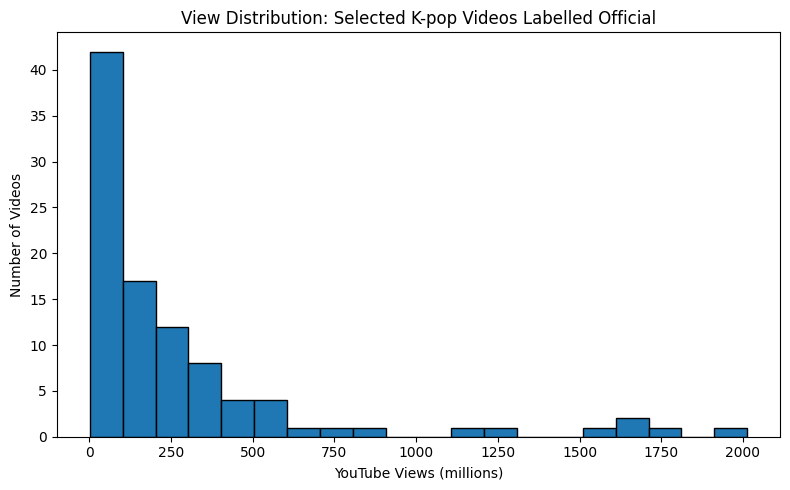

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    kpop_official['Views'] / 1_000_000,
    bins=20,
    edgecolor='black'
)

plt.xlabel('YouTube Views (millions)')
plt.ylabel('Number of Videos')
plt.title('View Distribution: Selected K-pop Videos Labelled Official')
plt.tight_layout()
plt.show()

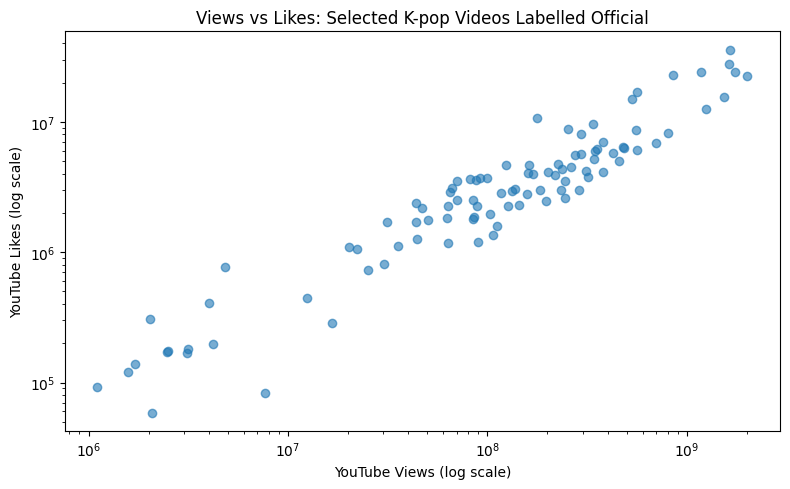

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    kpop_official['Views'],
    kpop_official['Likes'],
    alpha=0.6
)

plt.xscale('log')
plt.yscale('log')

plt.xlabel('YouTube Views (log scale)')
plt.ylabel('YouTube Likes (log scale)')
plt.title('Views vs Likes: Selected K-pop Videos Labelled Official')
plt.tight_layout()
plt.show()

In [ ]:
kpop_official['Like_Rate_Pct'] = (
    kpop_official['Likes'] / kpop_official['Views'] * 100
)

kpop_official[
    ['Artist', 'Track', 'Views', 'Likes', 'Like_Rate_Pct']
].head()

,Artist,Track,Views,Likes,Like_Rate_Pct
8067,TWICE,MOONLIGHT SUNRISE,50381801.0,1760260.0,3.493841
8068,TWICE,Talk that Talk,132108378.0,2951205.0,2.233927
8069,TWICE,The Feels,346384506.0,6026700.0,1.739887
8070,TWICE,FANCY,565262008.0,6056056.0,1.071371
8071,TWICE,What is Love,697538531.0,6845818.0,0.981425


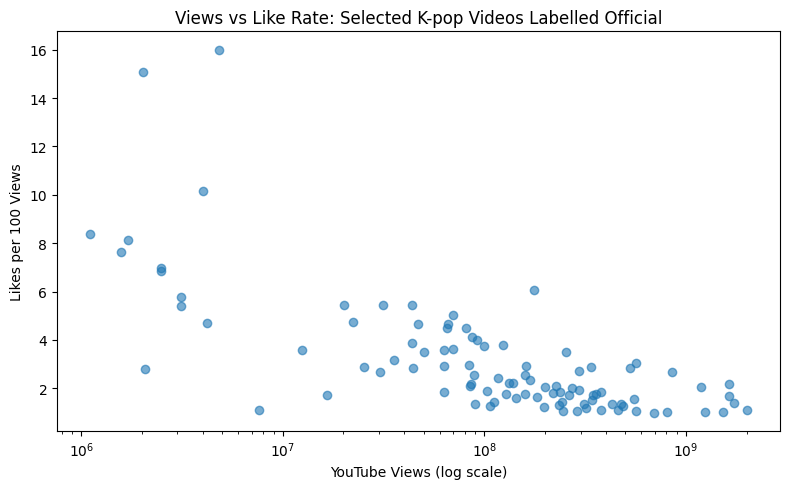

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    kpop_official['Views'],
    kpop_official['Like_Rate_Pct'],
    alpha=0.6
)

plt.xscale('log')
plt.xlabel('YouTube Views (log scale)')
plt.ylabel('Likes per 100 Views')
plt.title('Views vs Like Rate: Selected K-pop Videos Labelled Official')
plt.tight_layout()
plt.show()

In [ ]:
print(
    'Views vs Likes:',
    round(kpop_official['Views'].corr(
        kpop_official['Likes'], method='spearman'
    ), 3)
)

print(
    'Views vs Like Rate:',
    round(kpop_official['Views'].corr(
        kpop_official['Like_Rate_Pct'], method='spearman'
    ), 3)
)

Views vs Likes: 0.934
Views vs Like Rate: -0.721


In [ ]:
comparison = []

for name, data in [
    ('All matched videos', kpop_youtube),
    ('Labelled official', kpop_official)
]:
    like_rate = data['Likes'] / data['Views'] * 100

    comparison.append({
        'Sample': name,
        'N': len(data),
        'Views vs Likes': data['Views'].corr(
            data['Likes'], method='spearman'
        ),
        'Views vs Like Rate': data['Views'].corr(
            like_rate, method='spearman'
        )
    })

pd.DataFrame(comparison).round(3)

,Sample,N,Views vs Likes,Views vs Like Rate
0,All matched videos,109,0.953,-0.685
1,Labelled official,97,0.934,-0.721


In [ ]:
within_artist = []

for artist, data in kpop_official.groupby('Artist'):
    within_artist.append({
        'Artist': artist,
        'N': len(data),
        'Views vs Like Rate': data['Views'].corr(
            data['Like_Rate_Pct'], method='spearman'
        )
    })

pd.DataFrame(within_artist).round(3)

,Artist,N,Views vs Like Rate
0,BLACKPINK,8,-0.571
1,BTS,10,-0.939
2,ENHYPEN,9,-0.133
3,EXO,9,-0.567
4,ITZY,9,-0.533
5,NCT 127,8,-0.238
6,Red Velvet,8,-0.762
7,SEVENTEEN,8,-0.548
8,Stray Kids,9,-0.983
9,TOMORROW X TOGETHER,9,-0.950
